# <center>
<div style="
    background: #f0f333ff;
    border-left: 5px solid #ecd242ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h1 style="
        text-align: center;
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 600;
    ">
    Nettoyage
    </h1>
</div>

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Question
    </h2>
</div>

- Intégrer et tester le module fourni "validation_structure"
- Décider ce qu'est un doublon
- Appeler le service sur une vingtaine de numéros de pays diférents

###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Imports
    </h3>
</div>

In [410]:
# %reset

In [ ]:
import sys
import time
import requests

import missingno as msno
import pandas as pd
import matplotlib.pyplot as plt
# On importe le module

sys.path.append('../api')
from validation_structure import normaliser, valider

# Reading Data
df_csv = pd.read_csv('../data/numeros_tva.csv', index_col='id', sep=',', keep_default_na = False)
df_csv_bis = pd.read_csv('../data/numeros_tva.csv')
# Inutile de lire le fichier Excel
# df_xl  = pd.read_excel('../data/numeros_tva.xlsx', index_col='id', keep_default_na = False)

df_csv['raison_sociale'] = df_csv['raison_sociale'].str.strip()
df_csv['pays_declare'] = df_csv['pays_declare'].str.strip()
df_csv_init = df_csv.copy()

print(f'Nombre de ligne dans le CSV : {df_csv.shape[0]}')

Nombre de ligne dans le CSV : 10000


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Utilisation des fonctions "Normaliser" et "Valider" du module "validation_structure.py"
    </h3>
</div>

La fonction normaliser :
- Suppression des caractères spéciaux
- Passage en majuscule

La fonction valider :
- Appelle la fonction "normaliser"
- Vérifie que le numéro ne soit pas vide ou trop court
- Récupère le code pays et la partie numérique à partir du numéro complte de TVA
- Appelle la fonction de vérification correspondant au code pays (si le code pays est pris en charge)
- Renvoie le résultat de la fonction de vérification (True, False) ainsi que le motif de non validtion

**Exemple la fonction de vérificaiton française :**
```py
def _fr(n: str) -> bool:
    if not re.fullmatch(r"\d{11}", n):
        return False
    return int(n[:2]) == (12 + 3 * (int(n[2:]) % 97)) % 97


TVA France : 2 chiffres de clé + 9 chiffres de SIREN.

clé = (12 + 3 × (SIREN mod 97)) mod 97

Par exemple : FR27552032534 
On décompose le numéro en : clé = 27 
                            SIREN = 552032534
on vérifie :
    552032534 % 97 = 5
    (12 + 3 * 5) % 97 = 27
    On retombe bien sur la clé 27 donc ce numéro est valide
```

**Appel de la fonction 'Valider'**

In [412]:
# Normalisation des numéros
df_csv['numero_tva_norme'] = df_csv['numero_tva'].apply(normaliser)

# Validation des numéros
resultats = df_csv['numero_tva_norme'].apply(valider)

df_csv[['Verdict', 'Motif']] = pd.DataFrame(
    resultats.tolist(),
    index=df_csv.index,
    columns=['Verdict', 'Motif']
)

df_csv.sample(10)

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,numero_tva_norme,Verdict,Motif
id,,,,,,,,
8714,Lusitania Foods A/S,IT,IT2155178510K,2024-01-24,portail_client,IT2155178510K,False,cle_invalide
9351,Prima Consulting SAS,LU,LU676405052,2025-01-10,portail_client,LU676405052,False,cle_invalide
3269,Prima Technologies A/S,FI,FI66M95437,2024-02-11,saisie_manuelle,FI66M95437,False,cle_invalide
3637,Delta Technologies SAS,LU,LU 8778 9802,2025-01-16,portail_client,LU87789802,True,ok
8995,Cobalt Trading Sp. z o.o.,FI,FI61051266,2024-02-01,portail_client,FI61051266,True,ok
7091,Batavia Technologies NV,FR,FR824722735911,2025-06-08,portail_client,FR824722735911,False,cle_invalide
7021,Azur Trading SARL,SE,SE437183616601,2025-05-21,import_fournisseur,SE437183616601,True,ok
816,Baltic Foods BV,PT,PT85259984,2025-01-23,portail_client,PT85259984,False,cle_invalide
4790,Kappa Services GmbH,PT,PT765930536,2024-07-18,reprise_erp,PT765930536,True,ok


Motifs possibles : 

| Motif | Explication |
|:--:|:--:|
| `ok` | Le numéro de TVA est valide |
| `vide` | Le numéro de TVA est vide |
| `trop_court` | Le numéro est trop court (moins de 4 caractères) donc invalide |
| `pays_non_couvert` | L'indicatif du pays du numéro de TAV n'est pas pris en compte |
| `cle_invalide` | La clé du numéro de TAV est invalide |

###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Comptage du nombre de numéros valides et des motifs
    </h3>
</div>

In [413]:
print('-' * 8 + ' Après avoir normalisé les numéros ' + '-' * 8 + '\n')

ds = df_csv['Verdict'].value_counts()
print(f'Nombre de numéros valides   : {ds.values[0]}')
print(f'Nombre de numéros invalides : {ds.values[1]}')
print(f'Nombre de données total     : {df_csv.shape[0]}\n')

ds = df_csv['Motif'].value_counts()
print("Motifs des invalides :")
print(f'Nombre de numéros avec une clé invalide : {ds.values[1]}')
print(f"Nombre de numéros d'un pays non couvert : {ds.values[2]}")
print(f'Nombre de numéros vides                 : {ds.values[3]}')
print(f'Nombre de numéros trop courts           : {ds.values[4]}')
print(f'Total \t\t\t\t\t: {sum([ds.values[i] for i in range(1, 5)])}')

-------- Après avoir normalisé les numéros --------

Nombre de numéros valides   : 6083
Nombre de numéros invalides : 3917
Nombre de données total     : 10000

Motifs des invalides :
Nombre de numéros avec une clé invalide : 2605
Nombre de numéros d'un pays non couvert : 1090
Nombre de numéros vides                 : 174
Nombre de numéros trop courts           : 48
Total 					: 3917


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Nettoyage
    </h2>
</div>


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Sélection des pays couverts
    </h3>
</div>

On conserve uniquement les pays :<br>
"FR", "BE", "NL", "LU", "PT", "DK", "FI", "PL", "IT", "SE"

In [414]:
lst_countries = ["FR", "BE", "NL", "LU", "PT", "DK", "FI", "PL", "IT", "SE"]

print(f'Taille du dataset AVANT suppression des pays non couverts : {df_csv.shape[0]}')

# masque_2_lettres = df_csv['numero_tva_norme'].str.match(r'^[A-Za-z]{2}', na=False)
# masque_pays_connus = df_csv['pays_declare'].str[:2].isin(lst_countries)
# df_csv = df_csv[~(masque_2_lettres & ~masque_pays_connus)]
df_csv = df_csv[df_csv['pays_declare'].isin(lst_countries)]

print(f'Taille du dataset APRES suppression des pays non couverts : {df_csv.shape[0]}')

Taille du dataset AVANT suppression des pays non couverts : 10000
Taille du dataset APRES suppression des pays non couverts : 9481


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Suppression des "Faux Nan"
    </h3>
</div>

- NULL
- N/A
- NAN
- '_'

<Axes: >

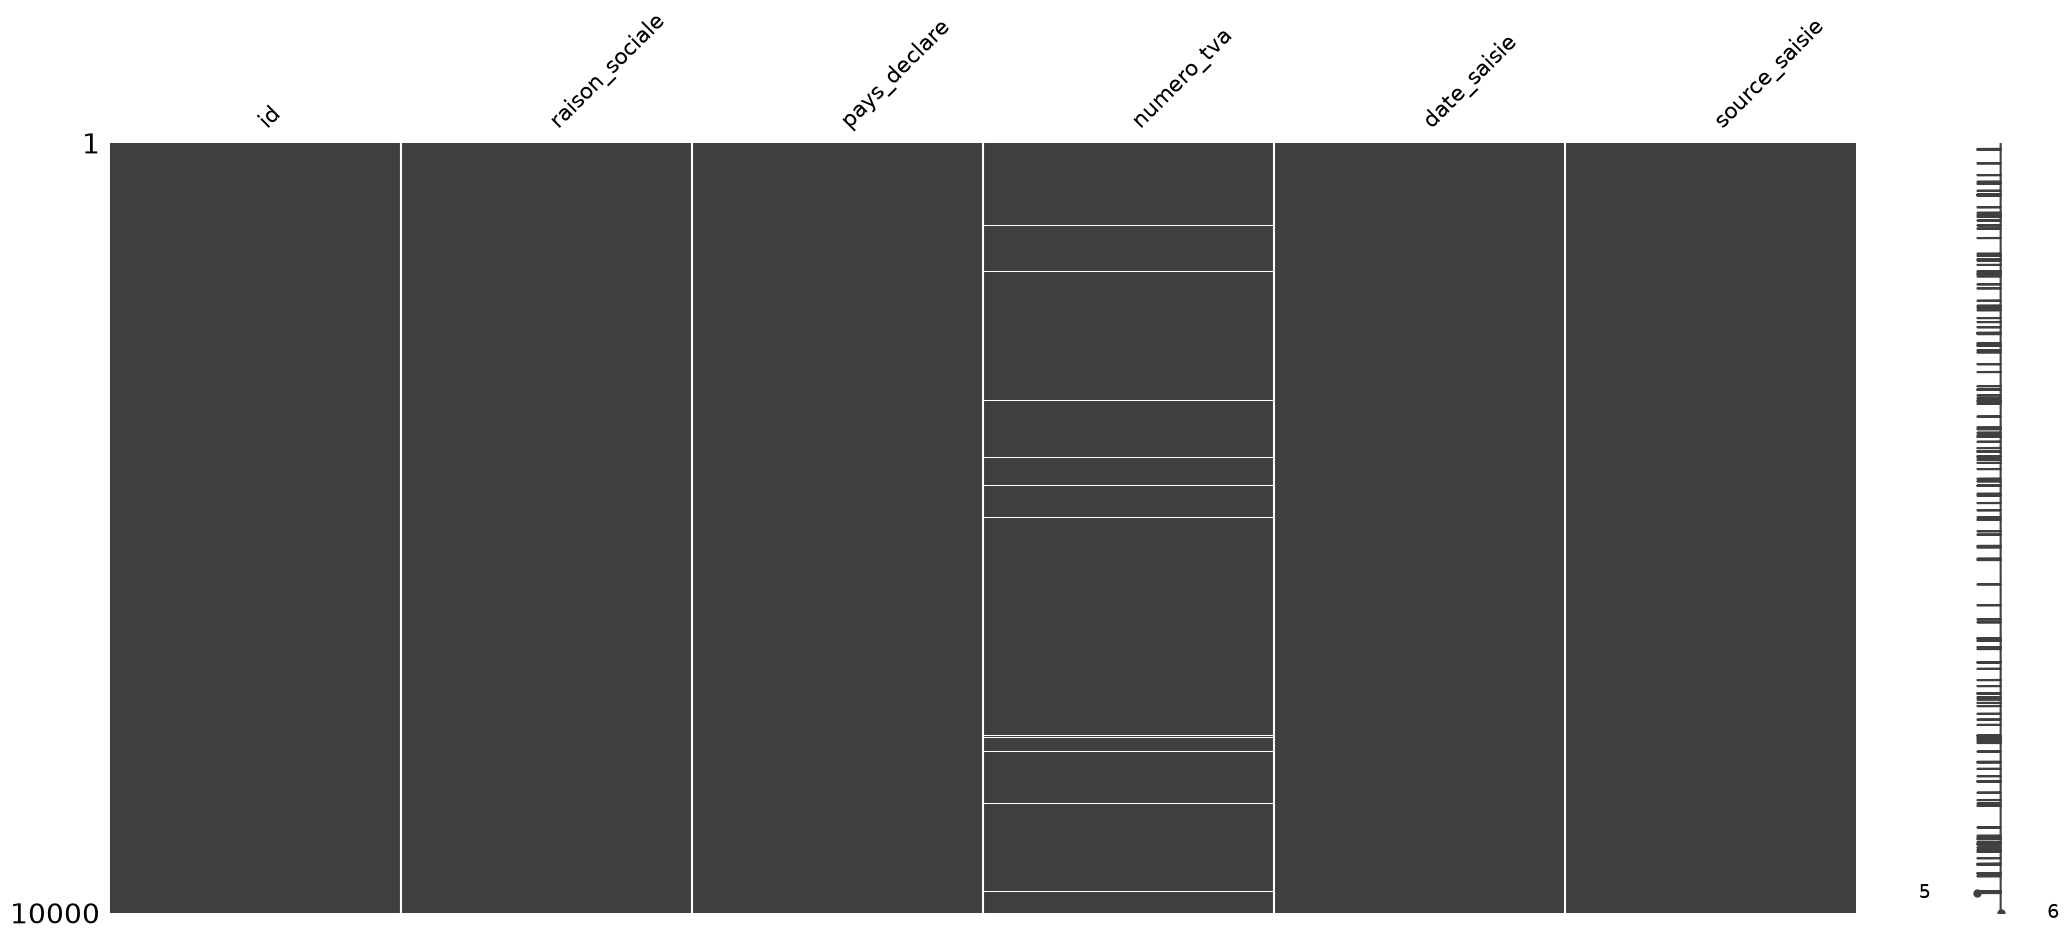

In [415]:
# Visualisation des NaN
msno.matrix(df_csv_bis)

In [416]:
print(f'Taille du dataset AVANT suppression des faux NaN : {df_csv.shape[0]}')
df_csv = df_csv[~df_csv['numero_tva_norme'].isin(['NULL', 'NA', 'NAN', ''])]
print(f'Taille du dataset APRES suppression des faux NaN : {df_csv.shape[0]}')

Taille du dataset AVANT suppression des faux NaN : 9481
Taille du dataset APRES suppression des faux NaN : 9220


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Ajout du code pays au numéro
    </h3>
</div>

On ajoute le code pays au numéro comme préfixe :
- 123456789 -> FR123456789

In [417]:
print(f"AVANT : Il y a {df_csv[~df_csv['numero_tva_norme'].str.match(r'^[A-Za-z]{2}', na=False)].shape[0]} numéros de TVA qui ne commencent pas par 2 lettres (sur un total de {df_csv.shape[0]})")

masque = ~df_csv['numero_tva_norme'].str.match(r'^[A-Za-z]{2}', na=False)

df_csv.loc[masque, 'numero_tva_norme'] = (
    df_csv.loc[masque, 'pays_declare'] +
    
    df_csv.loc[masque, 'numero_tva_norme']
)

print(f"APRES : Il y a {df_csv[~df_csv['numero_tva_norme'].str.match(r'^[A-Za-z]{2}', na=False)].shape[0]} numéros de TVA qui ne commencent pas par 2 lettres (sur un total de {df_csv.shape[0]})")

AVANT : Il y a 532 numéros de TVA qui ne commencent pas par 2 lettres (sur un total de 9220)
APRES : Il y a 0 numéros de TVA qui ne commencent pas par 2 lettres (sur un total de 9220)


In [418]:
display(df_csv['pays_declare'].value_counts())
print(f'Il y a {df_csv['pays_declare'].nunique()} pays différents dans le jeu de données')

pays_declare
FR    948
DK    938
LU    932
BE    930
SE    922
PT    921
NL    919
PL    919
IT    918
FI    873
Name: count, dtype: int64

Il y a 10 pays différents dans le jeu de données


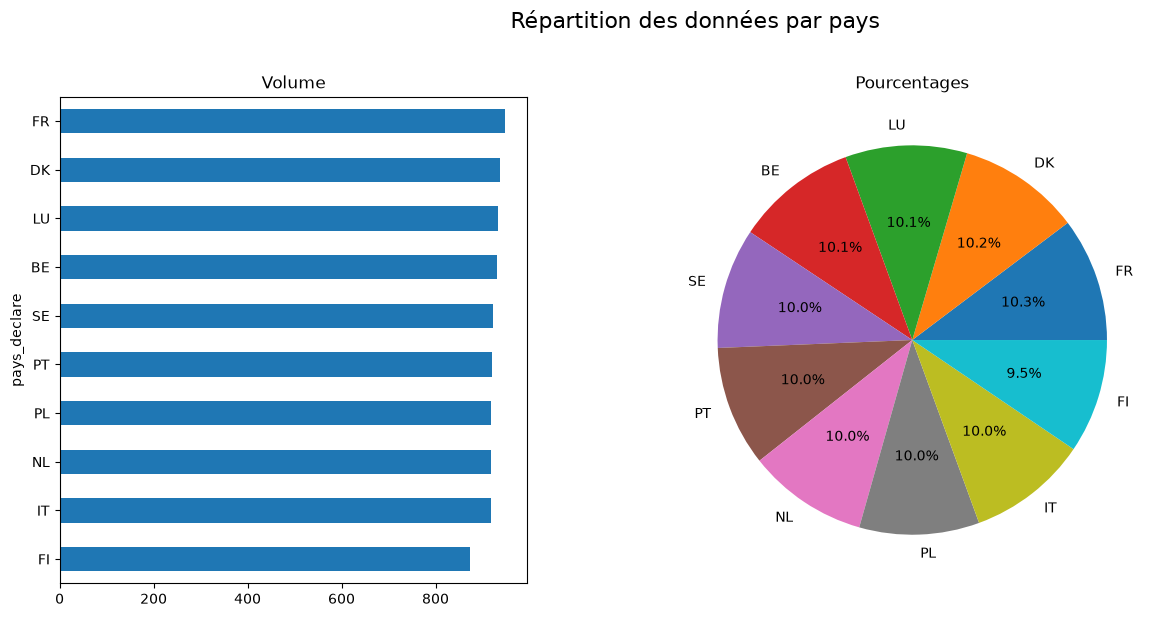

In [419]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),
                         gridspec_kw={'width_ratios' : [1, 2]})

df_csv['pays_declare'].value_counts(ascending=True).plot(
    kind='barh',
    ax=axes[0],
    title='Volume')
fig.suptitle('Répartition des données par pays', fontsize=16, y=1.02)

df_csv['pays_declare'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[1],
    title='Pourcentages'
)

plt.tight_layout()
plt.show()

###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Remplacement des O par 0
    </h3>
</div>

In [420]:
print(f"Il y a {df_csv[df_csv['numero_tva_norme'].str.contains('O')].shape[0]} caractère 'O' dans les numéros de TVA (sur un total de {df_csv.shape[0]})")
df_csv['numero_tva_norme'] = df_csv['numero_tva_norme'].str.replace('O', '0', regex=False)
print(f"Il y a {df_csv[df_csv['numero_tva_norme'].str.contains('O')].shape[0]} caractère 'O' dans les numéros de TVA (sur un total de {df_csv.shape[0]})")

Il y a 103 caractère 'O' dans les numéros de TVA (sur un total de 9220)
Il y a 0 caractère 'O' dans les numéros de TVA (sur un total de 9220)


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Recherche des doublons
    </h2>
</div>

Décidez ensuite de ce qu'est un doublon dans ce référentiel, et comptez-les. Votre définition doit pouvoir s'écrire en une phrase.

Nous allons chercher les doublons sur :
- Les numéros de TVA seuls
- Les couples : (numéros de TVA, raison sociale)
- Les lignes entières

####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Doublon sur les lignes entières
    </h3>
</div>

In [421]:
print(f'Il y a {df_csv[df_csv.duplicated()].shape[0]} doublons pour les lignes entières')

Il y a 0 doublons pour les lignes entières


####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Doublon sur les couples : (numéros de TVA, raison sociale)
    </h3>
</div>

In [422]:
# Doublon sur les numéros de TVA
df_duplicate = df_csv[df_csv[['numero_tva_norme', 'raison_sociale']].duplicated()].sort_values(by='numero_tva_norme')
print(f'Il y a {df_duplicate.shape[0]} doublons pour les couples (numero_tva_norme, raison_sociale)')
display(df_duplicate.value_counts(['numero_tva_norme', 'raison_sociale']))
df_duplicate

Il y a 419 doublons pour les couples (numero_tva_norme, raison_sociale)


numero_tva_norme  raison_sociale               
DK71704289        Lumen Technologies Sp. z o.o.    5
BE0282330178      Papyrus Industries SA            4
DK91970813        Ardent Foods Oy                  3
FI64379216        Papyrus Technologies AB          3
NL785427788B39    Vela Materials SpA               3
                                                  ..
SE749364685001    Vela Trading SARL                1
SE761636825901    Metallo Materials AB             1
SE793597541201    Prima Transports SARL            1
SE864512769001    Cobalt Industries A/S            1
SE980721039601    Verso Distribution A/S           1
Name: count, Length: 380, dtype: int64

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,numero_tva_norme,Verdict,Motif
id,,,,,,,,
1592,Azur Foods Lda,BE,BE-0187972912,2025-06-06,crm,BE0187972912,False,cle_invalide
7141,Alpine Trading NV,BE,BE027968584,2024-06-26,crm,BE027968584,False,cle_invalide
2458,Global Services SA,BE,BE.0280780446,2024-07-17,import_fournisseur,BE0280780446,False,cle_invalide
7777,Global Services SA,BE,BE0280780446,2024-12-03,import_fournisseur,BE0280780446,False,cle_invalide
1232,Papyrus Industries SA,BE,02.82330178,2024-10-13,reprise_erp,BE0282330178,False,pays_non_couvert
...,...,...,...,...,...,...,...,...
5604,Vela Trading SARL,SE,SE749364685001,2024-08-08,crm,SE749364685001,True,ok
9325,Metallo Materials AB,SE,761636825901,2024-11-04,saisie_manuelle,SE761636825901,False,pays_non_couvert
5097,Prima Transports SARL,SE,SE-793597541201,2024-09-06,import_fournisseur,SE793597541201,True,ok


####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Doublon sur les numéros de TVA seuls
    </h3>
</div>

In [423]:
df_duplicate = df_csv[df_csv['numero_tva_norme'].duplicated()]
print(f'Il y a {df_duplicate.shape[0]} doublons pour les numéros de TVA seuls')
display(df_duplicate.sort_values(by='numero_tva_norme'))
df_duplicate['numero_tva_norme'].value_counts()

Il y a 419 doublons pour les numéros de TVA seuls


,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,numero_tva_norme,Verdict,Motif
id,,,,,,,,
1592,Azur Foods Lda,BE,BE-0187972912,2025-06-06,crm,BE0187972912,False,cle_invalide
7141,Alpine Trading NV,BE,BE027968584,2024-06-26,crm,BE027968584,False,cle_invalide
2458,Global Services SA,BE,BE.0280780446,2024-07-17,import_fournisseur,BE0280780446,False,cle_invalide
7777,Global Services SA,BE,BE0280780446,2024-12-03,import_fournisseur,BE0280780446,False,cle_invalide
1232,Papyrus Industries SA,BE,02.82330178,2024-10-13,reprise_erp,BE0282330178,False,pays_non_couvert
...,...,...,...,...,...,...,...,...
5604,Vela Trading SARL,SE,SE749364685001,2024-08-08,crm,SE749364685001,True,ok
9325,Metallo Materials AB,SE,761636825901,2024-11-04,saisie_manuelle,SE761636825901,False,pays_non_couvert
5097,Prima Transports SARL,SE,SE-793597541201,2024-09-06,import_fournisseur,SE793597541201,True,ok


numero_tva_norme
DK71704289        5
BE0282330178      4
NL785427788B39    3
DK91970813        3
PT100405711       3
                 ..
NL442736873B35    1
DK48622259        1
SE342108454601    1
BE1769956921      1
FR60801776699     1
Name: count, Length: 380, dtype: int64

In [424]:
# Test un numéro en particulier
df_csv[(df_csv['numero_tva_norme'] == 'SE749364685001') & (df_csv['raison_sociale'] =='Papyrus Industries SA')]
df_csv[df_csv['numero_tva_norme'] == 'SE749364685001']

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,numero_tva_norme,Verdict,Motif
id,,,,,,,,
4812,Vela Trading SARL,SE,SE749364685001,2025-08-10,crm,SE749364685001,True,ok
5604,Vela Trading SARL,SE,SE749364685001,2024-08-08,crm,SE749364685001,True,ok


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Conclusion sur les doublons
    </h3>
</div>

Nous choisissons comme critère de "doublon" les numeros de TAV seuls car il y en a autant que si l'on cherche les doublons sur le critère (numero_tva_nor, raison_sociale).

In [425]:
print(f'Taille du dataset AVANT suppression des doublons : {df_csv.shape[0]}')
df_no_duplicate = df_csv.drop_duplicates(subset=['numero_tva_norme'])
print(f'Taille du dataset APRES suppression des doublons : {df_no_duplicate.shape[0]}')

Taille du dataset AVANT suppression des doublons : 9220
Taille du dataset APRES suppression des doublons : 8801


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Utilisation de la fonction "Valider" après nettoyage et suppression des doublons
    </h3>
</div>

In [426]:
resultats = df_no_duplicate['numero_tva_norme'].apply(valider)

df_no_duplicate[['Verdict', 'Motif']] = pd.DataFrame(
    resultats.tolist(),
    index=df_no_duplicate.index,
    columns=['Verdict', 'Motif']
)

print('-' * 8 + ' Après avoir normalisé les numéros sans doublon ' + '-' * 8 + '\n')
ds = df_no_duplicate['Verdict'].value_counts()
print(f'Nombre de numéros valides   : {ds.values[0]}')
print(f'Nombre de numéros invalides : {ds.values[1]}')
print(f'Nombre de données total     : {df_no_duplicate.shape[0]}\n')

ds = df_no_duplicate['Motif'].value_counts()
display(ds)
print("Motifs des invalides :")
print(f'Nombre de numéros avec une clé invalide : {ds.values[1]}')
assert ds.shape[0] == 2
print(f'Total \t\t\t\t\t: {sum([ds.values[i] for i in range(1, 2)])}')

-------- Après avoir normalisé les numéros sans doublon --------

Nombre de numéros valides   : 6311
Nombre de numéros invalides : 2490
Nombre de données total     : 8801



Motif
ok              6311
cle_invalide    2490
Name: count, dtype: int64

Motifs des invalides :
Nombre de numéros avec une clé invalide : 2490
Total 					: 2490


###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    On ne conserve que les numéros valides
    </h3>
</div>

À ce stade on sait que dans notre dataset de 10 000 donnnée il y a :
- 6311 numéros valides (la syntaxe est correcte et la structure clé + numéro est correcte)
- tous les autres sont soit vide, trop court, avec un mauvais préfixe, pays non couvert ou bien invalide (syntaxe incorrecte ou bien la structure clé + numéro est incorrecte)

In [427]:
df_valid = df_no_duplicate[df_no_duplicate['Verdict']]
df_invalid = df_no_duplicate[~df_no_duplicate['Verdict']]
display(df_valid.sample(10))
display(df_invalid.sample(10))

,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,numero_tva_norme,Verdict,Motif
id,,,,,,,,
7592,Corvus Industries SARL,PL,7303967928,2025-06-16,saisie_manuelle,PL7303967928,True,ok
4898,Azur Industries SpA,IT,IT40621862685,2025-06-01,import_fournisseur,IT40621862685,True,ok
2786,Kappa Distribution BV,SE,SE 3446 86281901,2024-10-23,saisie_manuelle,SE344686281901,True,ok
2758,Cobalt Industries A/S,PL,PL9002616968,2024-05-06,reprise_erp,PL9002616968,True,ok
3985,Atlantic Trading Oy,SE,SE320754706201,2025-04-15,portail_client,SE320754706201,True,ok
223,Meridian Transports BV,DK,DK 6315 1572,2025-05-28,reprise_erp,DK63151572,True,ok
1922,Nord Services Oy,SE,SE278117512601,2024-01-15,import_fournisseur,SE278117512601,True,ok
99,Fabrica Services SA,PT,PT116096764,2024-04-30,reprise_erp,PT116096764,True,ok
2565,Batavia Transports SA,SE,SE967890398101,2025-03-14,reprise_erp,SE967890398101,True,ok


,raison_sociale,pays_declare,numero_tva,date_saisie,source_saisie,numero_tva_norme,Verdict,Motif
id,,,,,,,,
1613,Alpine Trading SAS,DK,DK026597196,2024-10-03,saisie_manuelle,DK026597196,False,cle_invalide
765,Baltic Transports GmbH,SE,SE280781467701,2025-04-03,reprise_erp,SE280781467701,False,cle_invalide
4291,Orion Foods Oy,FI,FI27287717,2025-09-25,reprise_erp,FI27287717,False,cle_invalide
9801,Lusitania Consulting SpA,PT,PT805024633,2024-11-14,reprise_erp,PT805024633,False,cle_invalide
6385,Lumen Transports NV,FR,FR93175861445,2024-03-24,import_fournisseur,FR93175861445,False,cle_invalide
1880,Lumen Services A/S,NL,NL854971964B40,2025-08-20,portail_client,NL854971964B40,False,cle_invalide
5263,Prima Trading BV,NL,NL447647339B74,2025-09-30,saisie_manuelle,NL447647339B74,False,cle_invalide
8036,Vela Services Sp. z o.o.,DK,DK61523191,2024-05-20,reprise_erp,DK61523191,False,cle_invalide
5551,Lumen Transports Oy,IT,IT0613O561901,2025-09-13,reprise_erp,IT06130561901,False,cle_invalide


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Etude statistique
    </h2>
</div>

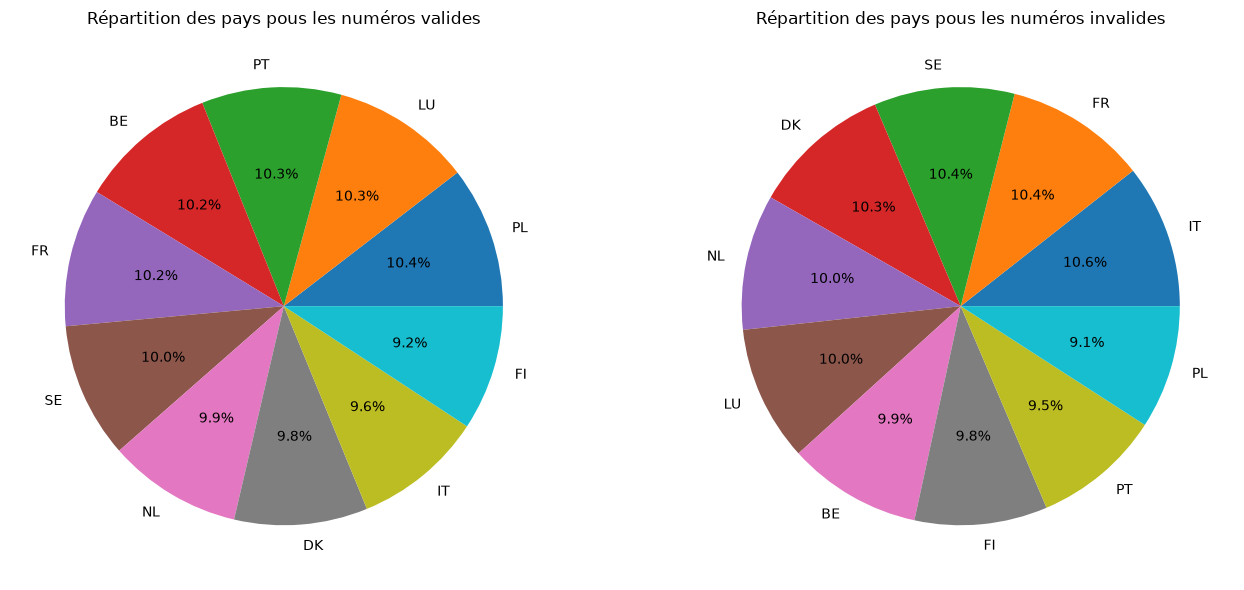

In [434]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),)

df_valid['pays_declare'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[0],
    title='Répartition des pays pous les numéros valides'
)

df_invalid['pays_declare'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[1],
    title='Répartition des pays pous les numéros invalides'
)

plt.tight_layout()
plt.show()

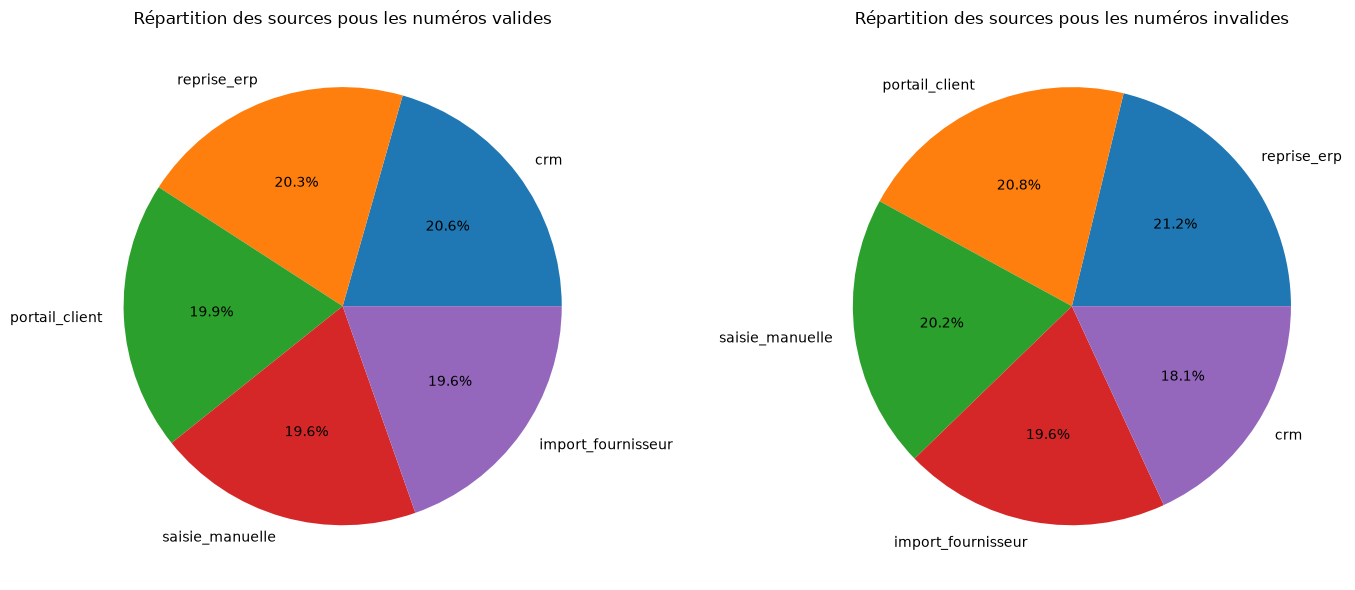

In [435]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6),)

df_valid['source_saisie'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[0],
    title='Répartition des sources pous les numéros valides'
)

df_invalid['source_saisie'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    ax=axes[1],
    title='Répartition des sources pous les numéros invalides'
)

plt.tight_layout()
plt.show()

##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Appel du service API (benchmark)
    </h2>
</div>

Nous allons lancer le service sur quelques numéros pour mesurer le temps de réponse.

####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Requête individuelle
    </h3>
</div>

In [449]:
code_pays = "PT"
numero = "513154671"
r = requests.get(f"https://ec.europa.eu/taxation_customs/vies/rest-api/ms/{code_pays}/vat/{numero}", timeout=10)
print(f"Code requête : {r.status_code}")

for k, v in r.json().items():
    print(f'{k} : {v}')

Code requête : 200
isValid : True
requestDate : 2026-11-18T15:43:06.014Z
userError : VALID
name : GUIMATUBOS TUBOS E SANITARIOS LDA
address : RUA DA INDIA N 374 R C LOJA 2 URGEZES
GUIMARÃES
4810-482 GUIMARAES
requestIdentifier : 
originalVatNumber : 513154671
vatNumber : 513154671
viesApproximate : {'name': '---', 'street': '---', 'postalCode': '---', 'city': '---', 'companyType': '---', 'matchName': 3, 'matchStreet': 3, 'matchPostalCode': 3, 'matchCity': 3, 'matchCompanyType': 3}


####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Requêtes groupées de l'API
    </h3>
</div>

In [ ]:
def request_api(df, size_sample):
    '''
        Requête l'API VIES (https://ec.europa.eu/taxation_customs/vies/rest-api/ms)
        Mémorise les verdicts des requêtes et les temps de réponse

        Args:
            df: DataFrame contenant les numéros de TVA
            size_sample: Nombre de numéro à requêter
        
        Returns:
            df_results : DatFrame contenant les verdicts de requêtes et les temps de réponse
            df_numero_to_check : DataFrame avec les pays+numéros qui ont donné des verdicts différents
                                 avec l'API et avec le script "valider" (cas à étudier individuellement)

    '''
    lst_sample = df[['numero_tva_norme', 'Verdict']].sample(size_sample).values.tolist()

    lst_countries, lst_numeros, lst_script_verdict, lst_api_verdict, lst_api_time = [], [], [], [], []
    lst_numeros_to_check = []

    global_time = time.time()

    for item in lst_sample:
        code_pays, numero = item[0][:2], item[0][2:]
        start = time.time()
        try:
            r = requests.get(f"https://ec.europa.eu/taxation_customs/vies/rest-api/ms/{code_pays}/vat/{numero}", timeout=10)
            elapsed_time = time.time() - start
            if r.status_code == 200:
                lst_countries.append(code_pays)
                lst_numeros.append(numero)
                lst_script_verdict.append(item[1])
                lst_api_verdict.append("VALID" if r.json()['isValid'] else "INVALID")
                lst_api_time.append(elapsed_time)

                if r.json()['isValid'] and item[1] != 'VALID':
                    # Si l'API renvoie VALID mais que notre script renvoie INVALID
                    lst_numeros_to_check.append([code_pays, numero])

        except requests.exceptions.Timeout:
            print(f'Délai dépassé : {item[0]}')
        time.sleep(1)

    print(f'Temps de traitement total : {time.time() - global_time}')

    df_results = pd.DataFrame({
        'Pays' : lst_countries,
        'Numero' : lst_numeros,
        'script_verdict' : lst_script_verdict,
        'api_verdict' : lst_api_verdict,
        'api_time' : lst_api_time
    })

    df_numero_to_check = pd.DataFrame({
        'Pays'   : [item[0] for item in lst_numeros_to_check],
        'numero' : [item[1] for item in lst_numeros_to_check]
    })

    print(f'Nombre de requêtes : {size_sample}')
    print(f'Moyenne du temps de requête : {sum(lst_api_time) / size_sample}')
    return df_results, df_numero_to_check

In [433]:
size_sample = 500
df_results, df_numero_to_check = request_api(df_valid, size_sample)

display(df_results.sample(min(20, df_results.shape[0])))

if not(df_numero_to_check.empty):
    display(df_numero_to_check.sample(min(10, df_numero_to_check.shape[0])))

path = "../data/results_benchmark.csv"
df_results.to_csv(path)

Délai dépassé : DK65470756
Délai dépassé : DK24208435
Délai dépassé : FI41140325
Délai dépassé : DK50329623
Délai dépassé : DK32165192
Délai dépassé : DK15011181
Temps de traitement total : 910.8919439315796
Nombre de requêtes : 500
Moyenne du temps de requête : 1.6956984486579896


,Pays,Numero,script_verdict,api_verdict,api_time
344,BE,0797739480,True,VALID,4.444120
232,PT,212327461,True,INVALID,0.656072
9,FI,71418316,True,INVALID,0.858970
148,NL,892103152B46,True,INVALID,2.198124
122,FI,61642613,True,INVALID,0.844850
110,LU,37122001,True,VALID,0.527406
308,FR,53603954541,True,INVALID,0.528800
201,FI,94374459,True,INVALID,0.773799
221,FR,42319432262,True,INVALID,0.519244
34,DK,49222955,True,INVALID,7.904656


,Pays,numero
0,LU,35907347
5,DK,50549151
3,LU,33340410
1,FI,91136826
4,LU,37122001
2,BE,0559903992
9,BE,0797739480
8,LU,24879439
12,DK,44945894
11,DK,42075442


In [ ]:
# df_results = pd.read_csv(path)

####
<div style="
    background: #eebbefff;
    border-left: 5px solid #d619efff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 400;
    ">
    Etude des temps de requête
    </h3>
</div>

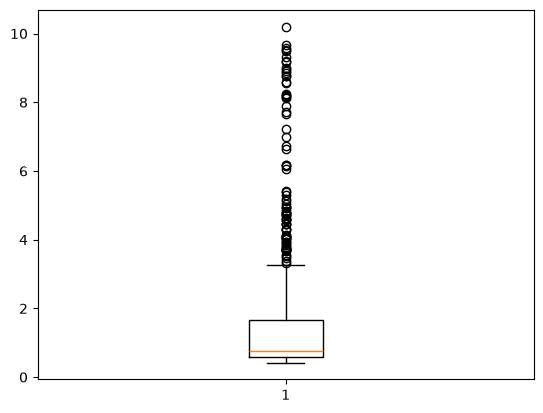

In [460]:
plt.boxplot(df_results['api_time'])
plt.show()

In [456]:
describe = df_results['api_time'].describe()
describe

count    494.000000
mean       1.716294
std        2.087789
min        0.422999
25%        0.596403
50%        0.756214
75%        1.660439
max       10.202811
Name: api_time, dtype: float64

Moyenne des temps de requêtes    : 1.72
Ecart-type des temps de requêtes : 2.09


<Axes: xlabel='Pays'>

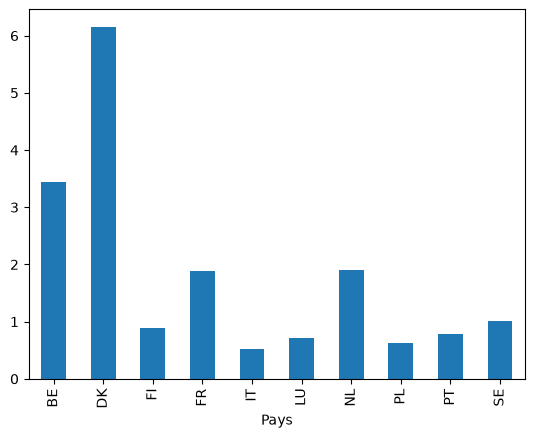

In [459]:
print(f'Moyenne des temps de requêtes    : {describe['mean']:.2f}')
print(f'Ecart-type des temps de requêtes : {describe['std']:.2f}')

df_results.groupby('Pays')['api_time'].mean().plot(kind='bar')

###
<div style="
    background: #9feaf2ff;
    border-left: 5px solid #1d28c1ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h3 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Estimation de la durée de campagne complète
    </h3>
</div>

In [497]:
def time_to_hours(tps):
    tps = int(tps)
    h = tps // 3600
    tps = tps % 3600
    m = tps // 60
    s = tps % 60
    return f'{h} h {m} min {s} sec'

print(f'Grâce au nettoyage nous sommes passés de : {df_csv_init.shape[0]} lignes à {df_valid.shape[0]}\n')

group = df_results.groupby('Pays')['api_time'].mean()
dico = dict(zip(group.index.values, group.values))

group = df_valid['pays_declare'].value_counts()
index_pays = group.index.values.tolist()
count_pays = group.values.tolist()

tps = sum([dico[index_pays[i]] * count_pays[i] for i in range(10)])
print(f"Le requêtage des {df_valid.shape[0]} numéros prendrait environ : {time_to_hours(tps)}")

Grâce au nettoyage nous sommes passés de : 10000 lignes à 6311

Le requêtage des 6311 numéros prendrait environ : 3 h 8 min 26 sec


In [474]:
df_results

,Pays,Numero,script_verdict,api_verdict,api_time
0,BE,0237863596,True,INVALID,4.084615
1,PL,2396758881,True,INVALID,0.728180
2,LU,75730088,True,INVALID,0.697327
3,FR,34405941483,True,INVALID,0.489745
4,LU,59956965,True,INVALID,0.564218
...,...,...,...,...,...
489,PL,6762668320,True,INVALID,0.627997
490,PT,690683421,True,INVALID,0.728043
491,PT,931427576,True,INVALID,0.658563
492,DK,98671021,True,INVALID,9.168453


##
<div style="
    background: #40f0aa;
    border-left: 5px solid #0c7230ff;
    padding: 15px 25px;
    margin: 20px 0;
    box-shadow: 0 2px 8px rgba(0,0,0,0.08);
">
    <h2 style="
        color: #2e3a59;
        font-family: 'Segoe UI', sans-serif;
        margin: 0;
        font-weight: 500;
    ">
    Récapitulatif des traitements
    </h2>
</div>


| Traitement | Nombre de numéros à vérifier |
|:--:|:--:|
| Initialement | 10000 |
| Suppression des pays non couverts | 9481 |
| Suppresion des faux NaN | 9220 |
| Ajout des codes pays aux numéros qui n'en ont pas | 9220 |
| Remplacement des O par 0 | 9220 |
| Suppression des doublons | 8801 |
| Application de la fonction 'valider' | 6311 |